---
title: "Oscillations — Level 2"
short_title: "05 Oscillations"
numbering:
  heading_2: true
  equation: true
---

# Oscillations

:::{seealso} Math for this topic
- [M4: Linear ODEs, Fourier series and transforms](../math/04-linear-odes-fourier.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 14 | Find the period and frequency of a specific spring–mass system |
| **2** | **Taylor, ch. 5** | **Solve the damped, driven oscillator in general; resonance, Fourier series, Green's functions** |
| 3 | Goldstein, ch. 6 | Small oscillations of many coupled degrees of freedom |

The new skill at this level: treating the oscillator as a linear system whose response to any force follows from its response to a sinusoid or a kick

Math for this topic: M4, linear ODEs, Fourier series and transforms.
:::

The math is in M4. This notebook is about what the solutions mean physically. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [M5: Calculus of variations](../math/05-calculus-of-variations.ipynb), the math for the next chapter. If you miss a part, study just the section it names and try that problem again.

1. **Why Oscillators Are Everywhere**

   A particle of mass $m$ moves in $U = U_0\left(\dfrac{a}{x} + \dfrac{x}{a}\right)$ for $x > 0$. Find the equilibrium and the frequency of small oscillations about it.

2. **Simple Harmonic Motion**

   A 0.50 kg mass on a spring with $k = 50$ N/m starts at $x_0 = 0.10$ m with $v_0 = 1.0$ m/s.

   (a) Find $\omega$ and the amplitude.

   (b) Find the phase $\delta$ in $x = A\cos(\omega t - \delta)$.

   (c) Find the total energy.

3. **Damped Oscillations**

   The same mass and spring now have damping $\beta = 2\ \text{s}^{-1}$ (in $\ddot x + 2\beta\dot x + \omega_0^2x = 0$).

   (a) Is the motion under-, over- or critically damped? Find the oscillation frequency.

   (b) Find $Q$ and the time for the energy to fall by a factor of $e$.

   (c) What damping constant $b$ would make it critically damped?

4. **Driven Oscillations and Resonance**

   A 1 kg oscillator with $\omega_0 = 20$ rad/s and $\beta = 0.5\ \text{s}^{-1}$ is driven by $F_0\cos\omega t$ with $F_0 = 2$ N.

   (a) Find the amplitude at resonance.

   (b) Find $Q$ and the approximate full width of the resonance peak in $\omega$.

   (c) What is the phase lag at resonance, and for $\omega \gg \omega_0$?

5. **Periodic Driving and Fourier Series**

   A square-wave force with fundamental frequency $\omega$ contains only odd harmonics. A lightly damped oscillator has $\omega_0 = 2\omega$. Does it respond strongly? What if $\omega_0 = 3\omega$?

6. **Arbitrary Forces: the Green's Function**

   An undamped oscillator at rest is pushed by a constant force $F_0$ for exactly one period, $0 < t < 2\pi/\omega_0$, and then the force is removed. What is the motion afterward? Explain physically.

7. **Electrical Analogue**

   An LRC circuit has $L = 10$ mH, $C = 1.0\ \mu$F and $R = 10\ \Omega$.

   (a) Which circuit elements play the roles of $m$, $b$ and $k$?

   (b) Find $\omega_0$ and $Q$.

:::{dropdown} Answers
1. $U' = 0$ at $x = a$. $U''(a) = 2U_0/a^2$, so $\omega = \sqrt{2U_0/(ma^2)}$.

2. (a) $\omega = 10$ rad/s and $A = \sqrt{x_0^2 + (v_0/\omega)^2} \approx 0.14$ m.

   (b) $\tan\delta = v_0/(\omega x_0) = 1$, so $\delta = \pi/4$.

   (c) $E = \tfrac12kA^2 = 0.50$ J.

3. (a) $\beta < \omega_0 = 10$, so it is underdamped, with $\omega_1 = \sqrt{\omega_0^2 - \beta^2} = \sqrt{96} \approx 9.8$ rad/s.

   (b) $Q = \omega_0/(2\beta) = 2.5$. The energy decays as $e^{-2\beta t}$, so the time is $1/(2\beta) = 0.25$ s.

   (c) $\beta = \omega_0$, so $b = 2m\omega_0 = 10$ kg/s.

4. (a) $A = \dfrac{F_0/m}{2\beta\omega_0} = 0.10$ m.

   (b) $Q = 20$, and the full width is about $2\beta = 1$ rad/s.

   (c) $90^\circ$ at resonance, approaching $180^\circ$ for $\omega \gg \omega_0$.

5. With $\omega_0 = 2\omega$, no: the second harmonic is absent. With $\omega_0 = 3\omega$, yes: the third harmonic is present and resonant.

6. It stays at rest at $x = 0$. During the push $x = (F_0/k)(1 - \cos\omega_0t)$, which returns to $x = 0$ with $\dot x = 0$ after exactly one period. In Green's function terms, the kicks from a whole period cancel.

7. (a) $L \leftrightarrow m$, $R \leftrightarrow b$ and $1/C \leftrightarrow k$.

   (b) $\omega_0 = 1/\sqrt{LC} = 1.0\times10^4$ rad/s, and $Q = \dfrac1R\sqrt{L/C} = 10$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Why Oscillators Are Everywhere

Near a stable equilibrium $x_0$, any smooth potential is approximately quadratic (see the energy notes):

$$
U(x)\approx U(x_0) + \tfrac12k(x - x_0)^2, \qquad k = U''(x_0) .
$$

So every system displaced slightly from stable equilibrium behaves like a mass on a spring, with $\omega_0 = \sqrt{k/m}$. Molecules, bridges, pendulums, circuits and stars all share this behavior for small motions.

## Simple Harmonic Motion

The equation $\ddot x = -\omega_0^2x$ has several equivalent forms of solution, each convenient for a different job:

$$
x(t) = A\cos(\omega_0t - \delta) = B_1\cos\omega_0t + B_2\sin\omega_0t = \operatorname{Re}\big(Ce^{i\omega_0t}\big) .
$$

The amplitude–phase form is easiest to picture, the $B_1, B_2$ form fits initial conditions directly ($B_1 = x_0$, $B_2 = v_0/\omega_0$), and the complex form is best for calculations. The energy $E = \tfrac12kA^2$ sloshes between kinetic and potential, and its time averages are equal: $\langle T\rangle = \langle U\rangle = E/2$.

In two dimensions, an **isotropic** oscillator ($k_x = k_y$) traces ellipses. An **anisotropic** one with commensurate frequencies traces closed **Lissajous figures**. With incommensurate frequencies the path never closes and eventually fills a rectangle.

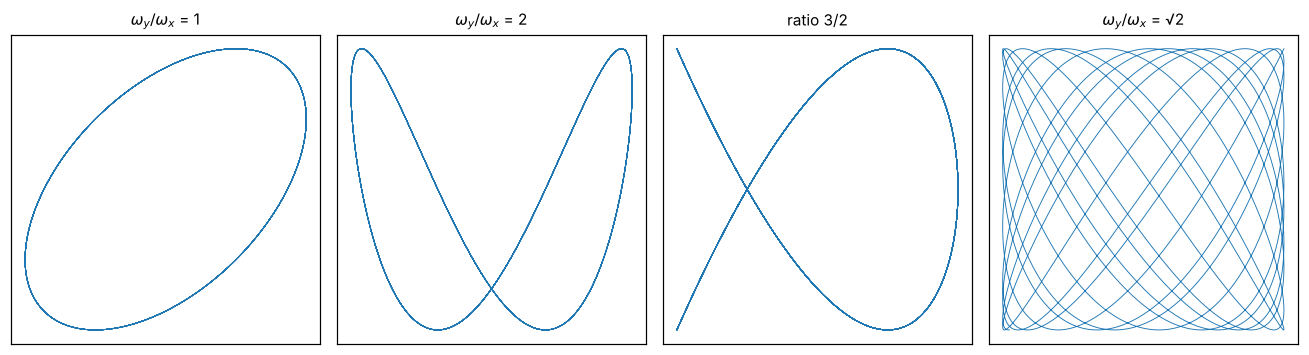

In [2]:
#| label: fig-lissajous
#| caption: Two-dimensional oscillators x = cos(ω_x t), y = cos(ω_y t − δ). Frequency ratios that are rational give closed Lissajous figures; an irrational ratio (right) never closes.
t = np.linspace(0, 60, 20000)
cases = [(1, 1, np.pi / 3), (1, 2, np.pi / 4), (2, 3, np.pi / 2), (1, np.sqrt(2), 0)]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (wx, wy, d) in zip(axes, cases):
    ax.plot(np.cos(wx * t), np.cos(wy * t - d), lw=0.6)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    lab = "√2" if wy == np.sqrt(2) else f"{wy}"
    ax.set_title(rf"$\omega_y/\omega_x$ = {lab}" if wx == 1 else f"ratio {wy}/{wx}", fontsize=10)
plt.tight_layout(); plt.show()

## Damped Oscillations

Add linear drag $-b\dot x$. With $\beta = b/2m$ (the **damping constant**), the equation of motion is

$$
\ddot x + 2\beta\dot x + \omega_0^2x = 0 ,
$$

and M4 gives three regimes:

- **Underdamped** ($\beta < \omega_0$): $x = Ae^{-\beta t}\cos(\omega_1t - \delta)$ with $\omega_1 = \sqrt{\omega_0^2 - \beta^2}$. It oscillates slightly slower than $\omega_0$ inside a decaying envelope.
- **Critically damped** ($\beta = \omega_0$): $x = (A + Bt)e^{-\beta t}$. It returns to equilibrium fastest without overshooting, which is the design goal for car suspensions and analog meters.
- **Overdamped** ($\beta > \omega_0$): a sum of two decaying exponentials. The slow one, with rate $\beta - \sqrt{\beta^2 - \omega_0^2}$, dominates, so heavy damping makes the return **slower**.

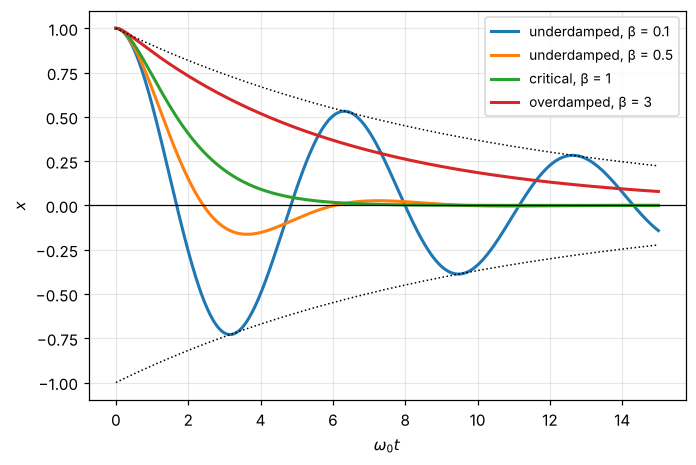

In [3]:
#| label: fig-damping
#| caption: Release from rest at x = 1 with ω₀ = 1. Underdamped motion overshoots and rings down; critical damping returns fastest without overshoot; heavy overdamping creeps back slowly.
w0 = 1.0
t = np.linspace(0, 15, 600)
fig, ax = plt.subplots()
for beta, lab in [(0.1, "underdamped, β = 0.1"), (0.5, "underdamped, β = 0.5"), (1.0, "critical, β = 1"), (3.0, "overdamped, β = 3")]:
    sol = solve_ivp(lambda s, y: [y[1], -2 * beta * y[1] - w0**2 * y[0]], (0, 15), [1, 0], t_eval=t, rtol=1e-9)
    ax.plot(t, sol.y[0], lw=2, label=lab)
ax.plot(t, np.exp(-0.1 * t), "k:", lw=1); ax.plot(t, -np.exp(-0.1 * t), "k:", lw=1)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(r"$\omega_0 t$"); ax.set_ylabel("$x$"); ax.legend(fontsize=9)
plt.show()

### Energy loss and the quality factor

For light damping, the energy $E\propto A^2e^{-2\beta t}$ decays at rate $2\beta$. The **quality factor**

$$
Q = \frac{\omega_0}{2\beta}
$$ (eq-q-factor)

measures how many oscillations happen before the energy decays: $Q$ is $2\pi$ times the energy stored divided by the energy lost per cycle. A struck tuning fork has $Q$ around $10^3$, a quartz watch crystal around $10^4$ to $10^5$, and a car's suspension around $1$.

## Driven Oscillations and Resonance

Now drive the oscillator with $F_0\cos\omega t$. With $f_0 = F_0/m$, M4 gives the steady state

$$
x_p = A\cos(\omega t - \delta), \qquad
A = \frac{f_0}{\sqrt{(\omega_0^2 - \omega^2)^2 + 4\beta^2\omega^2}}, \qquad
\tan\delta = \frac{2\beta\omega}{\omega_0^2 - \omega^2} .
$$ (eq-driven-response)

The full motion is this steady state plus a transient that decays at rate $\beta$.

- The amplitude peaks at $\omega_2 = \sqrt{\omega_0^2 - 2\beta^2}$, very close to $\omega_0$ for light damping, where it reaches $A_{\max}\approx f_0/(2\beta\omega_0)$.
- The phase lag $\delta$ goes from $0$ (slow drive, the mass follows the force) through $90^\circ$ at $\omega_0$ to $180^\circ$ (fast drive, the mass moves opposite to the force).
- The resonance peak's full width at half maximum **in power** is about $2\beta$, so $Q\approx\omega_0/\text{FWHM}$. The same $Q$ measures the ring-down time and the sharpness of the resonance.

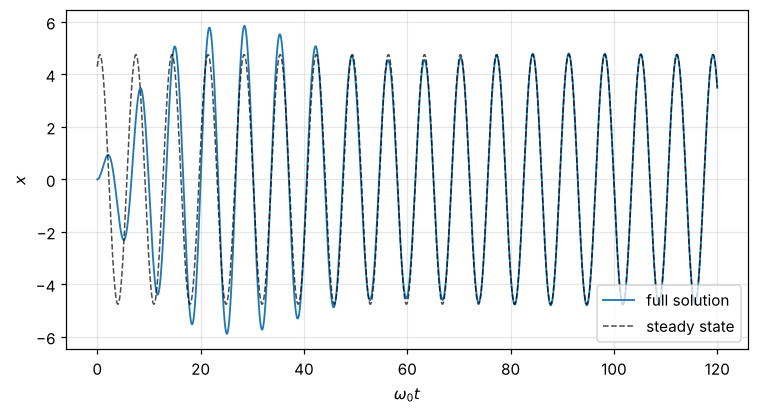

In [4]:
#| label: fig-transient
#| caption: A lightly damped oscillator (ω₀ = 1, β = 0.05) driven at ω = 0.9, starting from rest. Beats between the transient and the steady state die out on the timescale 1/β = 20, leaving the steady-state response (dashed).
w0, beta, w, f0 = 1.0, 0.05, 0.9, 1.0
t = np.linspace(0, 120, 6000)
sol = solve_ivp(lambda s, y: [y[1], f0 * np.cos(w * s) - 2 * beta * y[1] - w0**2 * y[0]], (0, 120), [0, 0], t_eval=t, rtol=1e-9)
A = f0 / np.sqrt((w0**2 - w**2)**2 + 4 * beta**2 * w**2)
d = np.arctan2(2 * beta * w, w0**2 - w**2)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, sol.y[0], lw=1.2, label="full solution")
ax.plot(t, A * np.cos(w * t - d), "k--", lw=1, alpha=0.7, label="steady state")
ax.set_xlabel(r"$\omega_0 t$"); ax.set_ylabel("$x$"); ax.legend(loc="lower right"); plt.show()

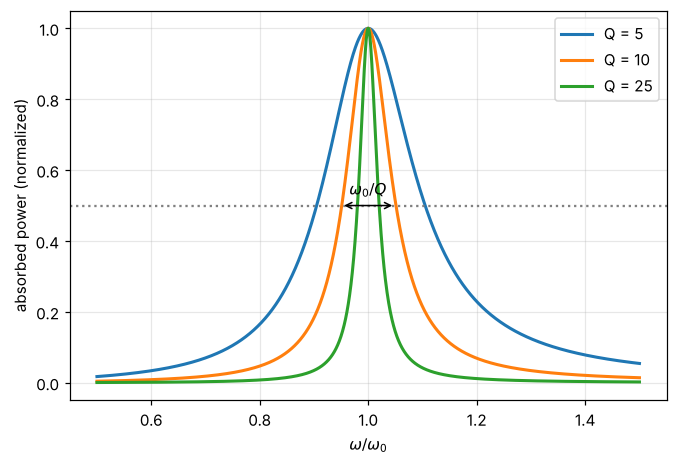

In [5]:
#| label: fig-power
#| caption: Average power absorbed from the drive, normalized to its peak, for Q = 5, 10 and 25. The peak sits at ω₀ and its full width at half maximum is ω₀/Q (marked for Q = 10).
w0 = 1.0
w = np.linspace(0.5, 1.5, 2000)
fig, ax = plt.subplots()
for Q in [5, 10, 25]:
    beta = w0 / (2 * Q)
    P = beta * w**2 / ((w0**2 - w**2)**2 + 4 * beta**2 * w**2)   # proportional to <P>
    ax.plot(w, P / P.max(), lw=2, label=f"Q = {Q}")
ax.axhline(0.5, color="gray", ls=":")
ax.annotate("", xy=(1 + 0.05, 0.5), xytext=(1 - 0.05, 0.5), arrowprops=dict(arrowstyle="<->", color="k"))
ax.text(1, 0.53, r"$\omega_0/Q$", ha="center")
ax.set_xlabel(r"$\omega/\omega_0$"); ax.set_ylabel("absorbed power (normalized)"); ax.legend(); plt.show()

In [6]:
# Peak position and height of the amplitude curve, symbolically
w, w0, beta, f0 = sp.symbols("omega omega_0 beta f_0", positive=True)
D = (w0**2 - w**2)**2 + 4 * beta**2 * w**2          # amplitude = f0 / sqrt(D)
w_peak = [s for s in sp.solve(sp.diff(D, w), w) if s != 0][0]
display(Math(r"\omega_{\text{peak}} = " + sp.latex(w_peak)))
display(Math(r"A_{\text{peak}} = " + sp.latex(sp.simplify(f0 / sp.sqrt(D.subs(w, w_peak))))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. A lightly damped oscillator's amplitude falls to $1/e$ of its initial value in $N$ cycles. Show that $Q\approx\pi N$.
2. Show that the time-averaged power delivered by the drive, $\langle F\dot x\rangle$, equals the power dissipated by damping, $\langle b\dot x^2\rangle$, in the steady state.
3. A 2 kg mass on a spring ($k = 200$ N/m) with $b = 4$ kg/s is driven by $F_0 = 10$ N. Find $Q$, the resonant amplitude, and the amplitude when driven at half the natural frequency.

:::{dropdown} Hints
1. The amplitude envelope is $e^{-\beta t}$, and $N$ cycles take $2\pi N/\omega_1\approx2\pi N/\omega_0$.
2. Over one cycle the stored energy returns to its starting value, so the net work must go somewhere.
3. $\omega_0 = 10$ rad/s, $\beta = 1$ s$^{-1}$, $f_0 = 5$ m/s². Use {eq}`eq-driven-response`.
:::

:::{dropdown} Answers
1. $\beta\cdot2\pi N/\omega_0 = 1$ gives $\beta = \omega_0/(2\pi N)$, so $Q = \omega_0/2\beta = \pi N$.
2. In the steady state the oscillator's energy is periodic, so over a cycle $\langle dE/dt\rangle = 0 = \langle F\dot x\rangle - \langle b\dot x^2\rangle$.
3. $Q = 5$. At resonance $A\approx f_0/(2\beta\omega_0) = 0.25$ m. At $\omega = 5$: $A = 5/\sqrt{75^2 + 100}\approx0.066$ m.
:::

## Periodic Driving and Fourier Series

A real drive (a piston, a plucked string, a pulsing star's driving cycle) is periodic but not sinusoidal. Expand the force in a Fourier series (M4), with drive frequency $\omega$:

$$
f(t) = \sum_n f_n\cos(n\omega t - \phi_n) .
$$

Each harmonic produces its own steady-state response from {eq}`eq-driven-response`, and linearity lets us add them:

$$
x(t) = \sum_n f_n\,|H(n\omega)|\cos\big(n\omega t - \phi_n - \delta_n\big) .
$$

The oscillator acts as a **filter**. A high-$Q$ oscillator responds strongly only to the harmonic closest to $\omega_0$, even if that harmonic is a small part of the drive.

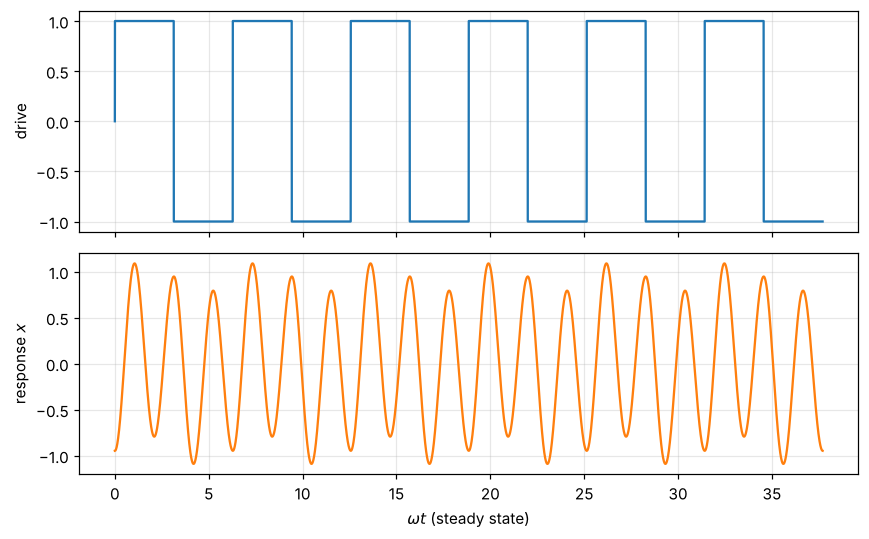

response amplitude per harmonic: {1: np.float64(0.159), 3: np.float64(0.943), 5: np.float64(0.016), 7: np.float64(0.005)}


In [7]:
#| label: fig-fourier-drive
#| caption: A square-wave drive at frequency ω applied to an oscillator tuned to ω₀ = 3ω (Q = 20). The square wave's fundamental is strongest, but the response (bottom) is almost a pure sinusoid at 3ω, because the oscillator picks out the resonant third harmonic.
w, w0, Q = 1.0, 3.0, 20
beta = w0 / (2 * Q)
t = np.linspace(0, 6 * 2 * np.pi, 6000)
T_end = 40 * 2 * np.pi
force = lambda s: np.sign(np.sin(w * s))
sol = solve_ivp(lambda s, y: [y[1], force(s) - 2 * beta * y[1] - w0**2 * y[0]], (0, T_end), [0, 0],
                t_eval=T_end - t[::-1], max_step=0.01, rtol=1e-8)
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(t, force(t), lw=1.5); axes[0].set_ylabel("drive")
axes[1].plot(t, sol.y[0], lw=1.5, color="tab:orange"); axes[1].set_ylabel("response $x$")
axes[1].set_xlabel(r"$\omega t$ (steady state)")
plt.tight_layout(); plt.show()

amps = {n: (4 / (n * np.pi)) / np.sqrt((w0**2 - (n * w)**2)**2 + 4 * beta**2 * (n * w)**2) for n in [1, 3, 5, 7]}
print("response amplitude per harmonic:", {n: round(a, 3) for n, a in amps.items()})

## Arbitrary Forces: the Green's Function

For a force that is not periodic at all (a gust, a single pulse, an earthquake), use the Green's function from M4:

$$
x(t) = \int_{-\infty}^{t}G(t - t')\,\frac{F(t')}{m}\,dt', \qquad G(t) = \frac{e^{-\beta t}\sin\omega_1t}{\omega_1}\,\Theta(t) .
$$

Physically, $G$ is the motion after a unit kick, and the integral adds up the kicks delivered at each earlier moment, each one ringing down at its own pace. The duration of the force compared with $1/\omega_0$ decides what happens:

- A force much **shorter** than the period acts like a kick: $x\approx(J/m)\,G(t)$, with $J$ the impulse.
- A force that switches on much **slower** than the period lets the oscillator follow along quasi-statically, and almost no ringing is left afterward.

This is why a slowly loaded bridge sags without vibrating while a sudden load sets it ringing.

## Electrical Analogue

The series RLC circuit obeys $L\ddot q + R\dot q + q/C = \mathcal{E}(t)$, the same equation:

| Mechanical | Electrical |
|---|---|
| displacement $x$ | charge $q$ |
| mass $m$ | inductance $L$ |
| damping $b$ | resistance $R$ |
| spring constant $k$ | $1/C$ |
| force $F$ | EMF $\mathcal{E}$ |

Every result here, including $Q$ and resonance widths, carries over directly. Radio tuning is a driven-oscillator resonance.

### Exercises

1. An undamped oscillator at rest receives a constant force $F_0$ switched on at $t = 0$. Use the Green's function to find $x(t)$.
2. A force $F(t) = F_0$ acts for a time $\Delta t\ll 2\pi/\omega_0$ on an undamped oscillator at rest. Find the amplitude of the oscillation afterward.

:::{dropdown} Hints
1. With $\beta = 0$, $G(t) = \sin(\omega_0t)/\omega_0$.
2. Treat it as a kick with impulse $F_0\Delta t$.
:::

:::{dropdown} Answers
1. $x = \frac{F_0}{k}(1 - \cos\omega_0t)$: oscillation about the new equilibrium $F_0/k$.
2. $A = F_0\Delta t/(m\omega_0)$.
:::

## Summary

- Small motions near any stable equilibrium are simple harmonic with $\omega_0 = \sqrt{U''/m}$.
- Damping gives underdamped, critical or overdamped motion. Critical damping returns fastest without overshoot.
- $Q = \omega_0/2\beta$ sets both the ring-down time and the resonance width.
- The driven steady state has amplitude and phase from {eq}`eq-driven-response`. The phase lag passes $90^\circ$ at resonance.
- Periodic drives are handled harmonic by harmonic with Fourier series, and the oscillator filters out all but the near-resonant ones.
- Arbitrary drives are handled with the Green's function: the response is a sum of ringing kicks.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.